# London Transport Network
## Complete Network Map with Geographic Coverage

This notebook visualizes the complete London transport network including all Underground lines, Elizabeth line, DLR, and Trams, with an overlay showing the geographic coverage area.

In [13]:
import pyarrow.feather as feather
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon, Circle
from matplotlib.collections import PatchCollection
from scipy.spatial import ConvexHull
from scipy.ndimage import gaussian_filter
from pathlib import Path

# Set up paths
DATA_DIR = Path('../data/processed_data')
OUTPUT_DIR = Path('../output')
OUTPUT_DIR.mkdir(exist_ok=True)

# All TfL line colors (official)
LINE_COLORS = {
    # Underground
    'BAK': '#B36305',  # Bakerloo - Brown
    'CEN': '#E32017',  # Central - Red
    'CIR': '#FFD300',  # Circle - Yellow
    'DIS': '#00782A',  # District - Green
    'HAM': '#F3A9BB',  # Hammersmith & City - Pink
    'JUB': '#A0A5A9',  # Jubilee - Grey
    'MET': '#9B0056',  # Metropolitan - Magenta
    'NTN': '#000000',  # Northern - Black
    'PIC': '#003688',  # Piccadilly - Dark Blue
    'VIC': '#0098D4',  # Victoria - Light Blue
    'WAC': '#95CDBA',  # Waterloo & City - Teal
    # Additional lines
    'DLR': '#00A4A7',  # DLR - Teal
    'ELZ': '#6950A1',  # Elizabeth - Purple
    'TRM': '#84B817',  # Trams - Lime Green
}

LINE_NAMES = {
    'BAK': 'Bakerloo',
    'CEN': 'Central',
    'CIR': 'Circle',
    'DIS': 'District',
    'HAM': 'Hammersmith & City',
    'JUB': 'Jubilee',
    'MET': 'Metropolitan',
    'NTN': 'Northern',
    'PIC': 'Piccadilly',
    'VIC': 'Victoria',
    'WAC': 'Waterloo & City',
    'DLR': 'DLR',
    'ELZ': 'Elizabeth',
    'TRM': 'Trams',
}

# Group lines by type for legend organization
UNDERGROUND_LINES = ['BAK', 'CEN', 'CIR', 'DIS', 'HAM', 'JUB', 'MET', 'NTN', 'PIC', 'VIC', 'WAC']
OTHER_LINES = ['DLR', 'ELZ', 'TRM']

## Load All Data

In [14]:
# Load stop points
stops = feather.read_feather(DATA_DIR / 'ALL-StopPoints.feather')
print(f"Loaded {len(stops)} stations")

# Convert coordinates
stops['Easting'] = pd.to_numeric(stops['Place_Location_Easting'])
stops['Northing'] = pd.to_numeric(stops['Place_Location_Northing'])

# Convert to lat/lon using pyproj
try:
    from pyproj import Transformer
    transformer = Transformer.from_crs('EPSG:27700', 'EPSG:4326', always_xy=True)
    coords = transformer.transform(stops['Easting'].values, stops['Northing'].values)
    stops['Longitude'] = coords[0]
    stops['Latitude'] = coords[1]
    print("Coordinate conversion: pyproj")
except ImportError:
    stops['Latitude'] = 49.0 + (stops['Northing'] / 111000)
    stops['Longitude'] = -7.5 + (stops['Easting'] / (111000 * np.cos(np.radians(stops['Latitude']))))
    print("Coordinate conversion: approximate")

# Create coordinate lookup
stop_coords = stops.set_index('AtcoCode')[['Easting', 'Northing', 'Latitude', 'Longitude', 'Descriptor_CommonName']].to_dict('index')

Loaded 691 stations
Coordinate conversion: pyproj


In [15]:
def load_route_links(line_code):
    """Load route links for a specific line."""
    path = DATA_DIR / f'{line_code}-RouteLinks.feather'
    if path.exists():
        return feather.read_feather(path)
    return None

def get_unique_edges(route_links):
    """Extract unique station-to-station edges."""
    return route_links[['From_StopPointRef', 'To_StopPointRef']].drop_duplicates()

# Load all lines
all_edges = {}
for line_code in LINE_COLORS.keys():
    links = load_route_links(line_code)
    if links is not None:
        edges = get_unique_edges(links)
        all_edges[line_code] = edges
        print(f"{LINE_NAMES[line_code]:20s}: {len(edges):4d} edges")
    else:
        print(f"{LINE_NAMES[line_code]:20s}: No data")

print(f"\nTotal lines loaded: {len(all_edges)}")

Bakerloo            :   48 edges
Central             :   98 edges
Circle              :  120 edges
District            :  122 edges
Hammersmith & City  :   74 edges
Jubilee             :   53 edges
Metropolitan        :   74 edges
Northern            :  106 edges
Piccadilly          :  115 edges
Victoria            :   30 edges
Waterloo & City     :    2 edges
DLR                 :   97 edges
Elizabeth           :   84 edges
Trams               :   71 edges

Total lines loaded: 14


In [16]:
def plot_line(ax, edges, stop_coords, color, linewidth=2, alpha=0.8):
    """Plot a single line on the axes."""
    for _, edge in edges.iterrows():
        from_stop = edge['From_StopPointRef']
        to_stop = edge['To_StopPointRef']
        
        if from_stop in stop_coords and to_stop in stop_coords:
            x = [stop_coords[from_stop]['Easting'], stop_coords[to_stop]['Easting']]
            y = [stop_coords[from_stop]['Northing'], stop_coords[to_stop]['Northing']]
            ax.plot(x, y, color=color, linewidth=linewidth, alpha=alpha, solid_capstyle='round')

def get_network_stations(all_edges, stop_coords):
    """Get all stations that are part of the network with valid coordinates."""
    stations = set()
    for edges in all_edges.values():
        stations.update(edges['From_StopPointRef'].tolist())
        stations.update(edges['To_StopPointRef'].tolist())
    return [s for s in stations if s in stop_coords]

## Complete Network Map

All lines displayed equally with their official TfL colors.

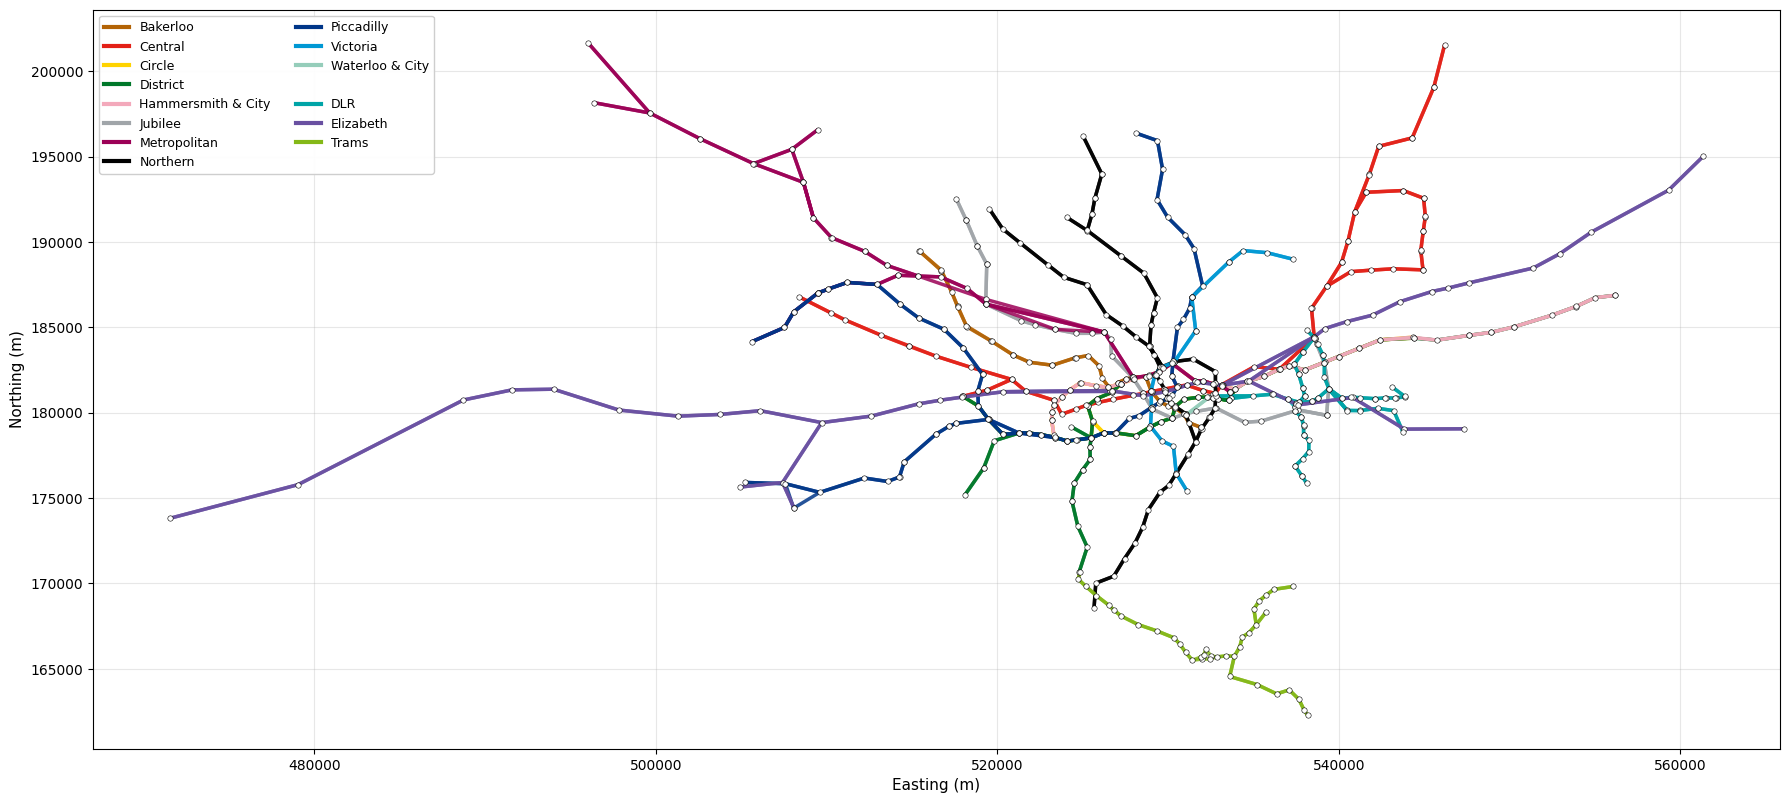

In [17]:
fig, ax = plt.subplots(figsize=(18, 20))

# Draw all lines with equal weight
for line_code in UNDERGROUND_LINES + OTHER_LINES:
    if line_code in all_edges:
        plot_line(ax, all_edges[line_code], stop_coords, 
                  LINE_COLORS[line_code], linewidth=2.5, alpha=0.85)

# Get all network stations
network_stations = get_network_stations(all_edges, stop_coords)

# Draw stations
for station in network_stations:
    ax.scatter(stop_coords[station]['Easting'], stop_coords[station]['Northing'],
              c='white', s=15, edgecolors='black', linewidth=0.4, zorder=10)

ax.set_xlabel('Easting (m)', fontsize=11)
ax.set_ylabel('Northing (m)', fontsize=11)
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)

# Create legend with all lines
legend_elements = []
# Underground lines
for code in UNDERGROUND_LINES:
    if code in all_edges:
        legend_elements.append(Line2D([0], [0], color=LINE_COLORS[code], linewidth=3, label=LINE_NAMES[code]))
# Separator
legend_elements.append(Line2D([0], [0], color='none', label=''))
# Other lines
for code in OTHER_LINES:
    if code in all_edges:
        legend_elements.append(Line2D([0], [0], color=LINE_COLORS[code], linewidth=3, label=LINE_NAMES[code]))

ax.legend(handles=legend_elements, loc='upper left', fontsize=9, ncol=2, framealpha=0.95)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'complete_network.png', dpi=150, bbox_inches='tight')
plt.show()

## Network with Geographic Coverage Area

The coverage area is calculated using a convex hull of all stations, representing the geographic extent of the network.

In [18]:
def create_coverage_hull(stations, stop_coords, buffer_m=1000):
    """Create a convex hull around all stations with optional buffer."""
    points = np.array([[stop_coords[s]['Easting'], stop_coords[s]['Northing']] 
                       for s in stations])
    
    hull = ConvexHull(points)
    hull_points = points[hull.vertices]
    
    # Add buffer by expanding from centroid
    if buffer_m > 0:
        centroid = np.mean(hull_points, axis=0)
        directions = hull_points - centroid
        distances = np.linalg.norm(directions, axis=1, keepdims=True)
        unit_directions = directions / distances
        hull_points = hull_points + unit_directions * buffer_m
    
    return hull_points

def create_smooth_boundary(stations, stop_coords, resolution=100, sigma=3):
    """Create a smoothed boundary using alpha shape approximation."""
    points = np.array([[stop_coords[s]['Easting'], stop_coords[s]['Northing']] 
                       for s in stations])
    
    # Get convex hull
    hull = ConvexHull(points)
    hull_points = points[hull.vertices]
    
    # Close the polygon
    hull_points = np.vstack([hull_points, hull_points[0]])
    
    # Interpolate more points along the boundary
    from scipy.interpolate import interp1d
    
    # Calculate cumulative distance along hull
    distances = np.sqrt(np.sum(np.diff(hull_points, axis=0)**2, axis=1))
    cumulative = np.concatenate([[0], np.cumsum(distances)])
    
    # Interpolate
    t_new = np.linspace(0, cumulative[-1], resolution)
    fx = interp1d(cumulative, hull_points[:, 0], kind='linear')
    fy = interp1d(cumulative, hull_points[:, 1], kind='linear')
    
    smooth_x = gaussian_filter(fx(t_new), sigma=sigma, mode='wrap')
    smooth_y = gaussian_filter(fy(t_new), sigma=sigma, mode='wrap')
    
    return np.column_stack([smooth_x, smooth_y])

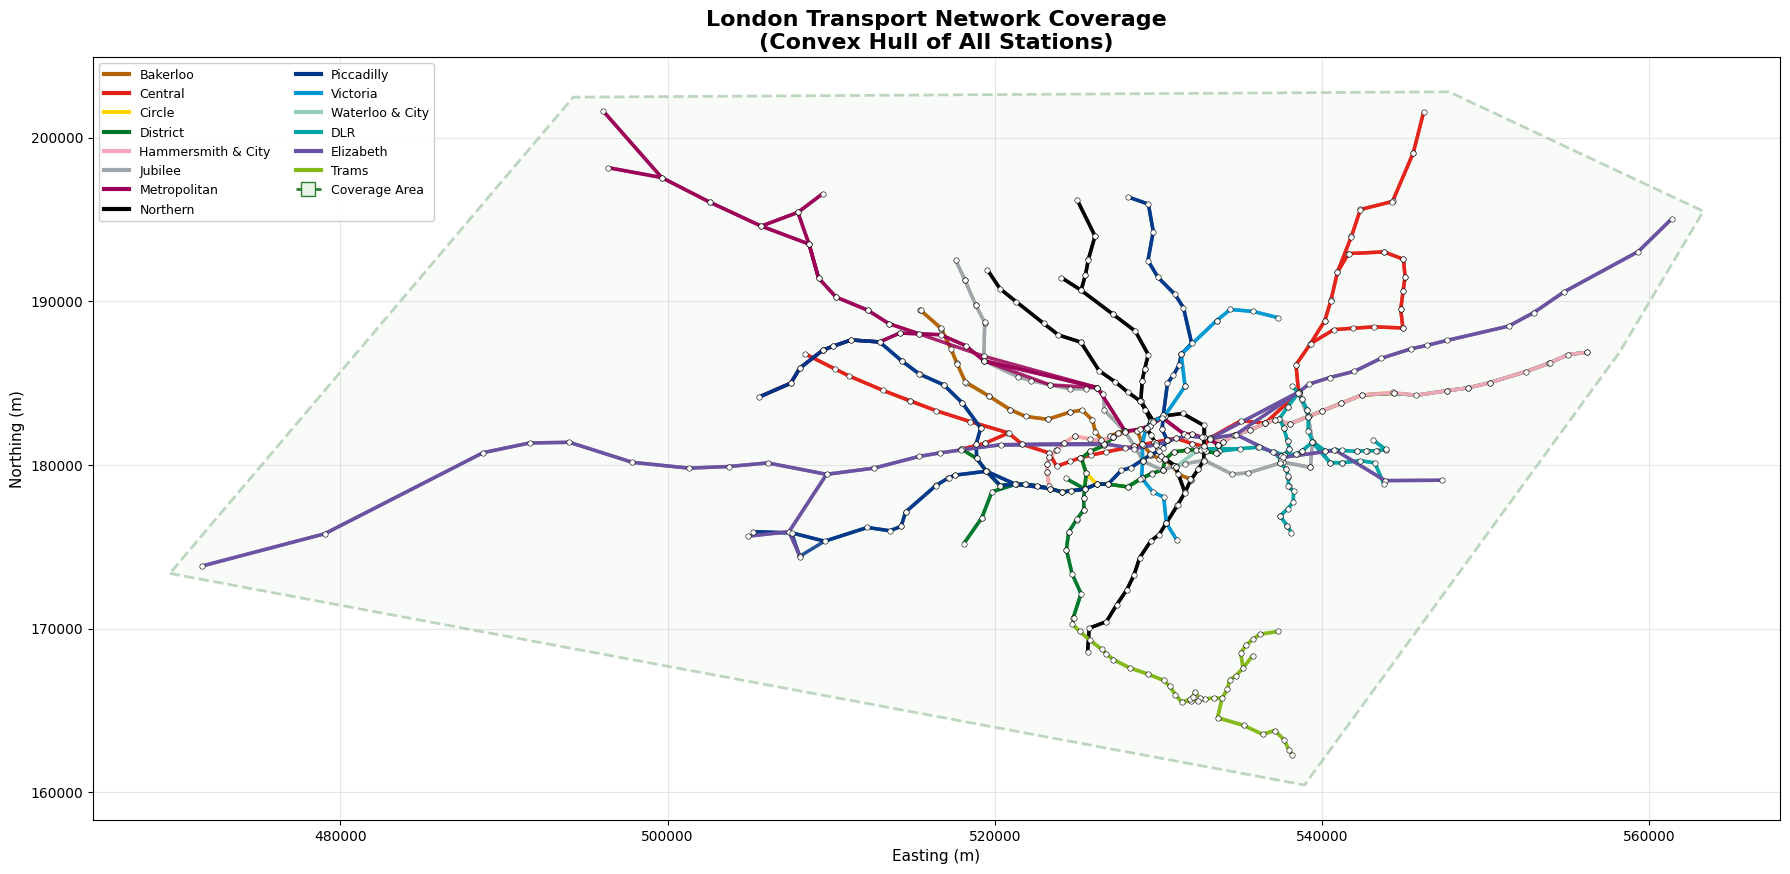

In [19]:
fig, ax = plt.subplots(figsize=(18, 20))

# Get network stations
network_stations = get_network_stations(all_edges, stop_coords)

# Create and draw coverage area
hull_points = create_coverage_hull(network_stations, stop_coords, buffer_m=2000)
coverage_polygon = Polygon(hull_points, closed=True, 
                           facecolor='#E8F4E8', edgecolor='#2E7D32', 
                           alpha=0.3, linewidth=2, linestyle='--',
                           zorder=1)
ax.add_patch(coverage_polygon)

# Draw all lines
for line_code in UNDERGROUND_LINES + OTHER_LINES:
    if line_code in all_edges:
        plot_line(ax, all_edges[line_code], stop_coords, 
                  LINE_COLORS[line_code], linewidth=2.5, alpha=0.85)

# Draw stations
for station in network_stations:
    ax.scatter(stop_coords[station]['Easting'], stop_coords[station]['Northing'],
              c='white', s=15, edgecolors='black', linewidth=0.4, zorder=10)

ax.set_xlabel('Easting (m)', fontsize=11)
ax.set_ylabel('Northing (m)', fontsize=11)
ax.set_title('London Transport Network Coverage\n(Convex Hull of All Stations)', fontsize=16, fontweight='bold')
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)

# Legend
legend_elements = []
for code in UNDERGROUND_LINES + OTHER_LINES:
    if code in all_edges:
        legend_elements.append(Line2D([0], [0], color=LINE_COLORS[code], linewidth=3, label=LINE_NAMES[code]))
# Add coverage area to legend
legend_elements.append(Line2D([0], [0], color='#2E7D32', linewidth=2, linestyle='--', 
                              marker='s', markersize=10, markerfacecolor='#E8F4E8', 
                              markeredgecolor='#2E7D32', label='Coverage Area'))

ax.legend(handles=legend_elements, loc='upper left', fontsize=9, ncol=2, framealpha=0.95)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'network_with_coverage.png', dpi=150, bbox_inches='tight')
plt.show()

## Network with Station Density Heatmap

Shows the concentration of stations across the network area.

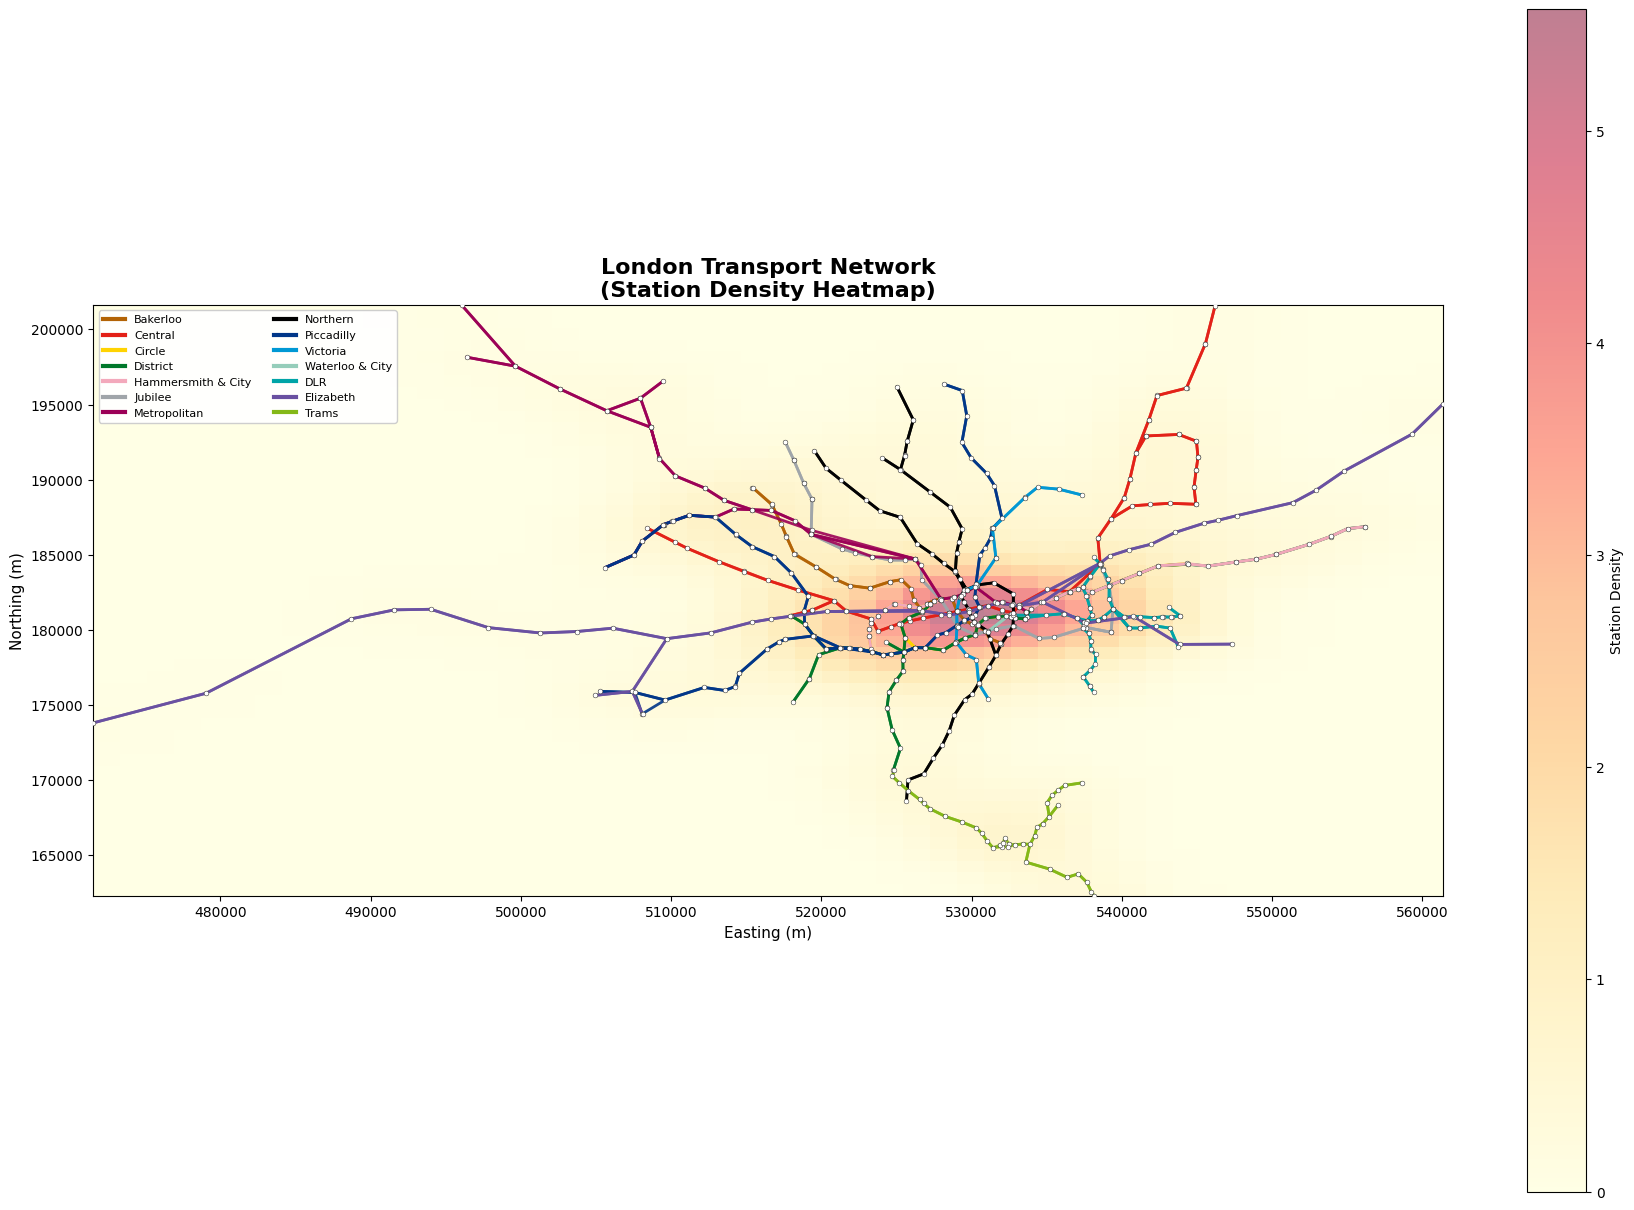

In [20]:
fig, ax = plt.subplots(figsize=(18, 20))

# Get station coordinates
network_stations = get_network_stations(all_edges, stop_coords)
station_x = [stop_coords[s]['Easting'] for s in network_stations]
station_y = [stop_coords[s]['Northing'] for s in network_stations]

# Create density heatmap
heatmap, xedges, yedges = np.histogram2d(station_x, station_y, bins=50)
heatmap = gaussian_filter(heatmap, sigma=2)

# Plot heatmap
extent = [xedges[0], xedges[-1], yedges[0], yedges[-1]]
im = ax.imshow(heatmap.T, extent=extent, origin='lower', cmap='YlOrRd', 
               alpha=0.5, aspect='auto', zorder=1)

# Draw all lines on top
for line_code in UNDERGROUND_LINES + OTHER_LINES:
    if line_code in all_edges:
        plot_line(ax, all_edges[line_code], stop_coords, 
                  LINE_COLORS[line_code], linewidth=2, alpha=0.9)

# Draw stations
for station in network_stations:
    ax.scatter(stop_coords[station]['Easting'], stop_coords[station]['Northing'],
              c='white', s=12, edgecolors='black', linewidth=0.3, zorder=10)

ax.set_xlabel('Easting (m)', fontsize=11)
ax.set_ylabel('Northing (m)', fontsize=11)
ax.set_title('London Transport Network\n(Station Density Heatmap)', fontsize=16, fontweight='bold')
ax.set_aspect('equal')

# Colorbar
cbar = plt.colorbar(im, ax=ax, shrink=0.6, label='Station Density')

# Legend
legend_elements = [Line2D([0], [0], color=LINE_COLORS[code], linewidth=3, label=LINE_NAMES[code])
                   for code in UNDERGROUND_LINES + OTHER_LINES if code in all_edges]
ax.legend(handles=legend_elements, loc='upper left', fontsize=8, ncol=2, framealpha=0.95)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'network_density.png', dpi=150, bbox_inches='tight')
plt.show()

## Network with Zone-Based Coverage

Approximate coverage zones based on distance from central London.

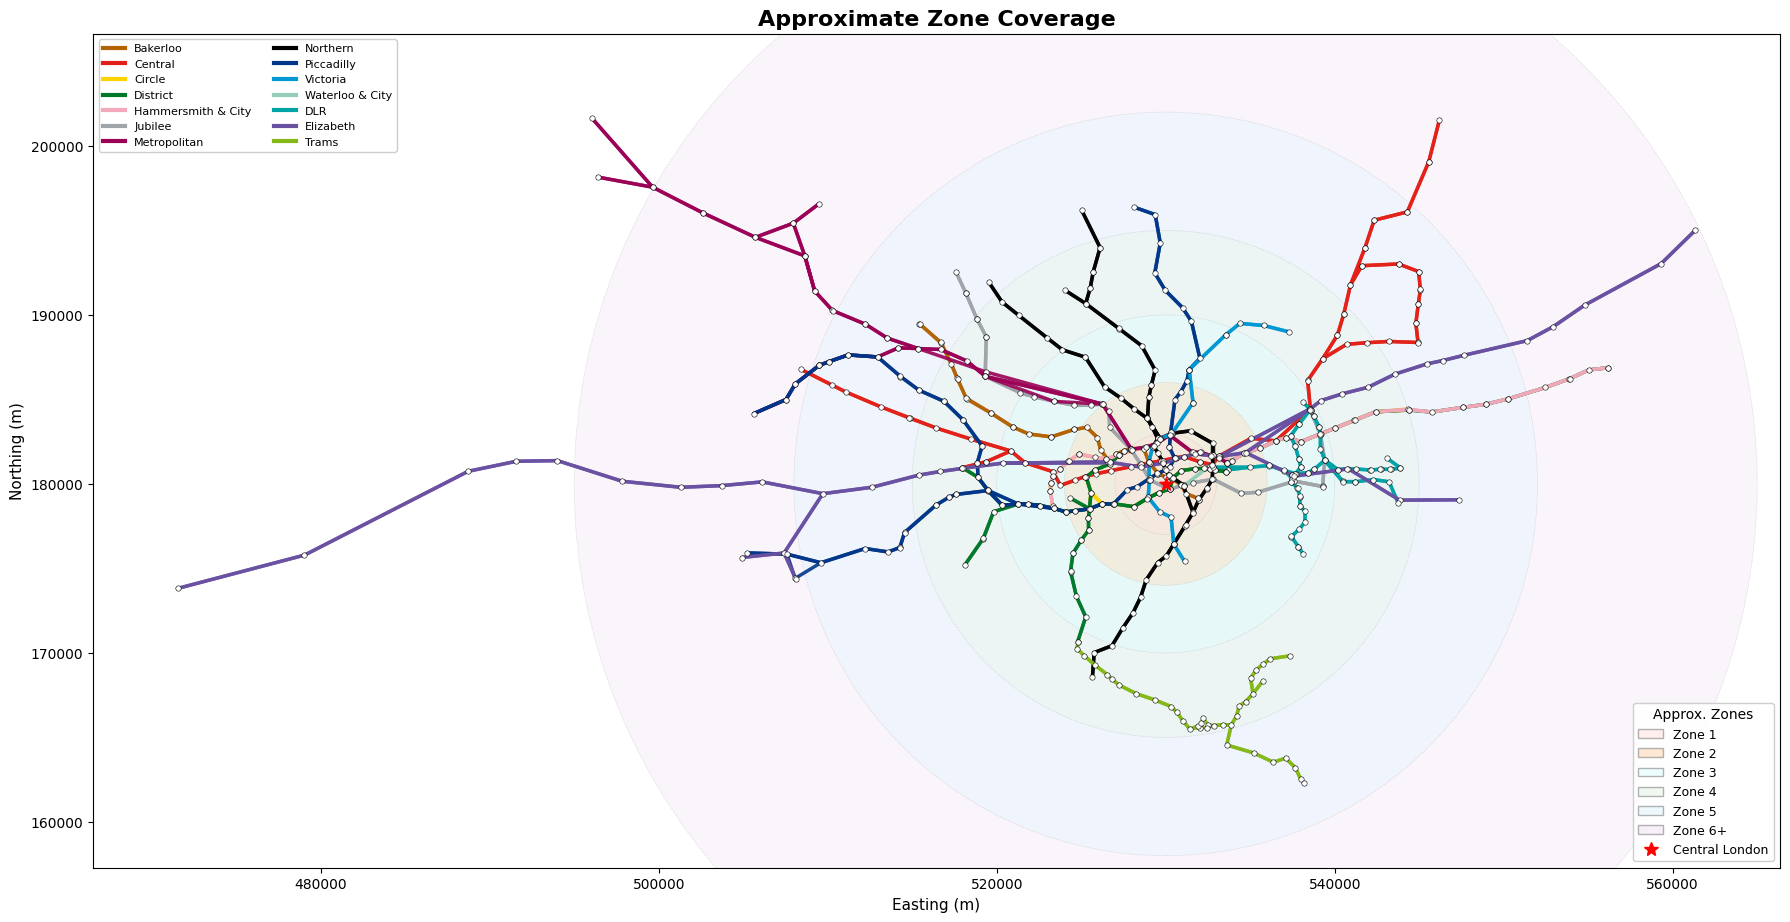

In [21]:
fig, ax = plt.subplots(figsize=(18, 20))

# Central London approximate coordinates (near Charing Cross)
# In OSGB36: approximately 530000, 180000
central_x, central_y = 530000, 180000

# Draw zone circles (approximate TfL fare zones)
zone_radii = [3000, 6000, 10000, 15000, 22000, 35000]  # meters
zone_colors = ['#FFE4E1', '#FFDAB9', '#E0FFFF', '#E8F5E9', '#E1F5FE', '#F3E5F5']
zone_labels = ['Zone 1', 'Zone 2', 'Zone 3', 'Zone 4', 'Zone 5', 'Zone 6+']

for radius, color in zip(reversed(zone_radii), reversed(zone_colors)):
    circle = Circle((central_x, central_y), radius, 
                    facecolor=color, edgecolor='gray', 
                    alpha=0.4, linewidth=0.5, linestyle=':', zorder=1)
    ax.add_patch(circle)

# Draw all lines
for line_code in UNDERGROUND_LINES + OTHER_LINES:
    if line_code in all_edges:
        plot_line(ax, all_edges[line_code], stop_coords, 
                  LINE_COLORS[line_code], linewidth=2.5, alpha=0.9)

# Draw stations
network_stations = get_network_stations(all_edges, stop_coords)
for station in network_stations:
    ax.scatter(stop_coords[station]['Easting'], stop_coords[station]['Northing'],
              c='white', s=15, edgecolors='black', linewidth=0.4, zorder=10)

# Mark central point
ax.scatter(central_x, central_y, c='red', s=100, marker='*', zorder=20, label='Central London')

ax.set_xlabel('Easting (m)', fontsize=11)
ax.set_ylabel('Northing (m)', fontsize=11)
ax.set_title('Approximate Zone Coverage', fontsize=16, fontweight='bold')
ax.set_aspect('equal')

# Set axis limits to show full network
all_x = [stop_coords[s]['Easting'] for s in network_stations]
all_y = [stop_coords[s]['Northing'] for s in network_stations]
margin = 5000
ax.set_xlim(min(all_x) - margin, max(all_x) + margin)
ax.set_ylim(min(all_y) - margin, max(all_y) + margin)

# Legend for lines
legend_elements = [Line2D([0], [0], color=LINE_COLORS[code], linewidth=3, label=LINE_NAMES[code])
                   for code in UNDERGROUND_LINES + OTHER_LINES if code in all_edges]
legend1 = ax.legend(handles=legend_elements, loc='upper left', fontsize=8, ncol=2, framealpha=0.95)
ax.add_artist(legend1)

# Legend for zones
zone_elements = [Circle((0, 0), 1, facecolor=color, edgecolor='gray', alpha=0.6, label=label)
                 for color, label in zip(zone_colors, zone_labels)]
zone_elements.append(Line2D([0], [0], marker='*', color='red', markersize=10, linestyle='', label='Central London'))
legend2 = ax.legend(handles=zone_elements, loc='lower right', fontsize=9, framealpha=0.95, title='Approx. Zones')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'network_zones.png', dpi=150, bbox_inches='tight')
plt.show()

## Network Statistics

In [22]:
print("=" * 60)
print("LONDON TRANSPORT NETWORK STATISTICS")
print("=" * 60)

total_stations = len(get_network_stations(all_edges, stop_coords))
total_edges = sum(len(edges) for edges in all_edges.values())

print(f"\nTotal Stations: {total_stations}")
print(f"Total Connections: {total_edges}")
print(f"Total Lines: {len(all_edges)}")

# Calculate network extent
network_stations = get_network_stations(all_edges, stop_coords)
all_x = [stop_coords[s]['Easting'] for s in network_stations]
all_y = [stop_coords[s]['Northing'] for s in network_stations]

width_km = (max(all_x) - min(all_x)) / 1000
height_km = (max(all_y) - min(all_y)) / 1000

print(f"\nNetwork Extent:")
print(f"  Width (E-W): {width_km:.1f} km")
print(f"  Height (N-S): {height_km:.1f} km")

# Coverage area (convex hull)
points = np.array([[stop_coords[s]['Easting'], stop_coords[s]['Northing']] 
                   for s in network_stations])
hull = ConvexHull(points)
coverage_km2 = hull.volume / 1e6  # Convert m² to km²
print(f"  Coverage Area: {coverage_km2:.1f} km²")

print("\n" + "-" * 60)
print("BY LINE:")
print("-" * 60)
print(f"{'Line':<25} {'Stations':>10} {'Connections':>12} {'Length (km)':>12}")
print("-" * 60)

for line_code in UNDERGROUND_LINES + OTHER_LINES:
    if line_code not in all_edges:
        continue
    
    edges = all_edges[line_code]
    line_stations = set(edges['From_StopPointRef'].tolist() + edges['To_StopPointRef'].tolist())
    valid_stations = [s for s in line_stations if s in stop_coords]
    
    # Calculate total length
    total_length = 0
    for _, edge in edges.iterrows():
        from_stop = edge['From_StopPointRef']
        to_stop = edge['To_StopPointRef']
        if from_stop in stop_coords and to_stop in stop_coords:
            dx = stop_coords[to_stop]['Easting'] - stop_coords[from_stop]['Easting']
            dy = stop_coords[to_stop]['Northing'] - stop_coords[from_stop]['Northing']
            total_length += np.sqrt(dx**2 + dy**2)
    
    print(f"{LINE_NAMES[line_code]:<25} {len(valid_stations):>10} {len(edges):>12} {total_length/1000:>12.1f}")

print("=" * 60)

LONDON TRANSPORT NETWORK STATISTICS

Total Stations: 691
Total Connections: 1094
Total Lines: 14

Network Extent:
  Width (E-W): 89.8 km
  Height (N-S): 39.3 km
  Coverage Area: 2385.8 km²

------------------------------------------------------------
BY LINE:
------------------------------------------------------------
Line                        Stations  Connections  Length (km)
------------------------------------------------------------
Bakerloo                          43           48         45.1
Central                           79           98        142.5
Circle                           113          120         99.4
District                         109          122        124.6
Hammersmith & City                68           74         75.0
Jubilee                           37           53         71.0
Metropolitan                      64           74        155.8
Northern                          77          106        116.6
Piccadilly                        89          115  